# Board games: combined exploratory data analysis

This notebook brings together Lilja, Pietro and Kristoffer's original EDA and the loading, text cleaning, joins and exports from `combined_notebook.ipynb`. Cornelius's section implements the notes for columns 14–26; no separate notebook was supplied for that section. The team ranges below are assignment labels, while columns are selected by name.

Run the notebook from top to bottom. Dependencies are listed in the repository's `environment.yml`. Existing local or Kaggle-cached CSVs are reused; missing source files are downloaded with `kagglehub`. The original data remains in `games`; each person's subset has its own dataframe. The final cells export `Data/combined_boardgames.csv` and the existing quantile sample to `Data/quantile_games.xlsx`.

## Shared setup and source data

Import the shared libraries once for all four sections.

In [ ]:
import ast
import html
import re
from itertools import combinations
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm
from scipy.stats import mannwhitneyu

Find the Boardgames folder and reuse local or cached files before downloading the three source CSVs. Only the requested files are downloaded, rather than the large reviews dataset.

In [ ]:
boardgames_dir = Path.cwd()
if (boardgames_dir / "Boardgames").is_dir():
    boardgames_dir = boardgames_dir / "Boardgames"
data_dir = boardgames_dir / "Data"
data_dir.mkdir(exist_ok=True)

def dataset_file(dataset, filename):
    local_file = data_dir / dataset.split("/")[-1] / filename
    if local_file.exists():
        return local_file
    cache_dir = Path.home() / ".cache" / "kagglehub" / "datasets" / dataset / "versions"
    if cache_dir.exists():
        versions = sorted(cache_dir.iterdir(), key=lambda p: int(p.name) if p.name.isdigit() else -1, reverse=True)
        for version in versions:
            if (version / filename).exists():
                return version / filename
    return Path(kagglehub.dataset_download(dataset, path=filename))

path_original = dataset_file("threnjen/board-games-database-from-boardgamegeek", "games.csv")
path_mechanics = dataset_file("andrewmvd/board-games", "bgg_dataset.csv")
path_detailed = dataset_file("jvanelteren/boardgamegeek-reviews", "games_detailed_info2025.csv")
for path in [path_original, path_mechanics, path_detailed]:
    print(path)

/Users/efh/.cache/kagglehub/datasets/threnjen/board-games-database-from-boardgamegeek/versions/4/games.csv
/Users/efh/.cache/kagglehub/datasets/andrewmvd/board-games/versions/2/bgg_dataset.csv
/Users/efh/.cache/kagglehub/datasets/jvanelteren/boardgamegeek-reviews/versions/4/games_detailed_info2025.csv


Repair HTML entities and incorrectly decoded UTF-8 using the text-cleaning functions from the original combined notebook.

In [ ]:
_cp1252_high = bytes(range(0x80, 0xA0)).decode("cp1252", errors="ignore")
_cont = f"[\x80-\xbf{_cp1252_high}]"
_mojibake = re.compile(f"[\xc2-\xdf]{_cont}|[\xe0-\xef]{_cont}{{2}}|[\xf0-\xf4]{_cont}{{3}}")

def _fix_mojibake(match):
    """Turn a garbled character sequence back into its bytes and decode them as UTF-8."""
    raw = bytes(ord(ch) if ord(ch) < 256 else ch.encode("cp1252")[0] for ch in match.group())
    try:
        return raw.decode("utf-8")
    except UnicodeDecodeError:
        return match.group()

def clean_text(s):
    """Unescape HTML entities and repair mis-decoded UTF-8, repeating until the text stops changing."""
    if not isinstance(s, str):
        return s
    prev = None
    while prev != s:
        prev, s = s, _mojibake.sub(_fix_mojibake, html.unescape(s))
    return re.sub("[\x80-\x9f]", "", s)

def clean_text_columns(df):
    """Apply clean_text to every text column of a dataframe."""
    for col in df.select_dtypes(["object", "string"]).columns:
        df[col] = df[col].map(clean_text)
    return df

Load the original games and the two enrichment datasets. These datasets come from different snapshots, so their added fields may have different coverage.

In [ ]:
games = clean_text_columns(pd.read_csv(path_original))
games_mechanics = clean_text_columns(pd.read_csv(path_mechanics, sep=";"))
games_detailed = clean_text_columns(pd.read_csv(
    path_detailed, usecols=["id", "description", "boardgamemechanic", "boardgamedesigner"]
))
for name, data in [("Original", games), ("Mechanics", games_mechanics), ("Detailed", games_detailed)]:
    print(f"{name}: {data.shape[0]:,} rows, {data.shape[1]} columns")
    display(data.head())

Original: 21,925 rows, 48 columns


,BGGId,Name,Description,YearPublished,GameWeight,AvgRating,BayesAvgRating,StdDev,MinPlayers,MaxPlayers,...,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,1,Die Macher,die macher game seven sequential political rac...,1986,4.3206,7.61428,7.10363,1.57979,3,5,...,21926,21926,0,1,0,0,0,0,0,0
1,2,Dragonmaster,dragonmaster tricktaking card game base old ga...,1981,1.9630,6.64537,5.78447,1.45440,3,4,...,21926,21926,0,1,0,0,0,0,0,0
2,3,Samurai,samurai set medieval japan player compete gain...,1998,2.4859,7.45601,7.23994,1.18227,2,4,...,21926,21926,0,1,0,0,0,0,0,0
3,4,Tal der Könige,triangular box luxurious large block tal der k...,1992,2.6667,6.60006,5.67954,1.23129,2,4,...,21926,21926,0,0,0,0,0,0,0,0
4,5,Acquire,acquire player strategically invest business t...,1964,2.5031,7.33861,7.14189,1.33583,2,6,...,21926,21926,0,1,0,0,0,0,0,0


Mechanics: 20,343 rows, 14 columns


,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,"8,79",1,"3,86",68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,"8,61",2,"2,84",65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,"8,66",3,"3,91",28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,"8,43",4,"3,24",87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,"8,70",5,"4,22",16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


Detailed: 27,780 rows, 4 columns


,id,description,boardgamemechanic,boardgamedesigner
0,13,"In CATAN (formerly The Settlers of Catan), pla...","['Chaining', 'Dice Rolling', 'Hexagon Grid', '...",['Klaus Teuber']
1,822,Carcassonne is a tile placement game in which ...,"['Area Majority / Influence', 'Enclosure', 'Ma...",['Klaus-Jürgen Wrede']
2,30549,"In Pandemic, several virulent diseases have br...","['Action Points', 'Cooperative Game', 'Hand Ma...",['Matt Leacock']
3,68448,You are the leader of one of the 7 great citie...,"['Closed Drafting', 'Hand Management', 'Neighb...",['Antoine Bauza']
4,167791,"In the 2400s, mankind begins to terraform the ...","['Closed Drafting', 'Contracts', 'End Game Bon...",['Jacob Fryxelius']


Use the original missing-value helper for fields where zero represents unavailable information. Binary indicators and genuine zero counts are analysed separately.

In [ ]:
def is_missing(s):
    """True where a value is NaN, 0 (numeric columns) or an empty list/blank (text columns)."""
    if pd.api.types.is_numeric_dtype(s):
        return s.isna() | (s == 0)
    t = s.astype("string").str.strip()
    return s.isna() | t.isin(["", "[]", "0"])

## Lilja — columns 1–13: ratings, players and language

Select Lilja’s original columns by name, excluding `StdDev` as requested. The original descriptions remain available for this overview.

In [ ]:
lilja_cols = [
    "Name", "Description", "YearPublished", "GameWeight", "AvgRating", "BayesAvgRating",
    "MinPlayers", "MaxPlayers", "ComAgeRec", "LanguageEase", "BestPlayers", "GoodPlayers",
]
games_lilja = games[lilja_cols].copy()
display(games_lilja.head())

,Name,Description,YearPublished,GameWeight,AvgRating,BayesAvgRating,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,GoodPlayers
0,Die Macher,die macher game seven sequential political rac...,1986,4.3206,7.61428,7.10363,3,5,14.366667,1.395833,5,"['4', '5']"
1,Dragonmaster,dragonmaster tricktaking card game base old ga...,1981,1.9630,6.64537,5.78447,3,4,NaN,27.000000,0,[]
2,Samurai,samurai set medieval japan player compete gain...,1998,2.4859,7.45601,7.23994,2,4,9.307692,1.000000,3,"['2', '3', '4']"
3,Tal der Könige,triangular box luxurious large block tal der k...,1992,2.6667,6.60006,5.67954,2,4,13.000000,256.000000,0,[]
4,Acquire,acquire player strategically invest business t...,1964,2.5031,7.33861,7.14189,2,6,11.410256,21.152941,4,"['3', '4', '5']"


Check missing values, zero placeholders and empty player lists without changing the source dataframe.

In [ ]:
missing = games_lilja.apply(is_missing)

overview = pd.DataFrame({
    "dtype": games_lilja.dtypes,
    "NaN": games_lilja.isna().sum(),
    "zero": games_lilja.select_dtypes("number").eq(0).sum().reindex(games_lilja.columns, fill_value=0),
    "empty_list": games_lilja.apply(lambda s: s.astype("string").str.strip().eq("[]").sum() if pd.api.types.is_string_dtype(s) else 0),
    "missing_total": missing.sum(),
    "missing_pct": (missing.mean() * 100).round(2),
    "unique_values": games_lilja.nunique(),
})
overview

,dtype,NaN,zero,empty_list,missing_total,missing_pct,unique_values
Name,str,0,0,0,0,0.00,21521
Description,str,1,0,0,1,0.00,21903
YearPublished,int64,0,193,0,193,0.88,188
GameWeight,float64,0,506,0,506,2.31,3921
AvgRating,float64,0,0,0,0,0.00,20489
BayesAvgRating,float64,0,0,0,0,0.00,15950
MinPlayers,int64,0,50,0,50,0.23,11
MaxPlayers,int64,0,173,0,173,0.79,54
ComAgeRec,float64,5530,0,0,5530,25.22,1366
LanguageEase,float64,5891,0,0,5891,26.87,3794


Keep Lilja’s density and player-count plotting helper, with shared colours and plot limits.

In [ ]:
CONTINUOUS = {"GameWeight": None, "YearPublished": (1950, 2021), "ComAgeRec": None, "LanguageEase": None}
DISCRETE = {"MaxPlayers": 10, "BestPlayers": 8, "MinPlayers": 6}
BLUE, RED = "#2a6f97", "#d1495b"

def capped_labels(s, cap):
    s = s.dropna().astype(int)
    return s.where(s <= cap, cap).map(lambda v: f"{cap}+" if v == cap else str(v))

def plot_against(target, data):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), layout="constrained")
    axes = axes.ravel()
    ylim = (np.floor(data[target].min()), np.ceil(data[target].max()))
    norm = LogNorm(vmin=1, vmax=3000)            # same colour scale in every density panel

    for ax, (col, lim) in zip(axes[:4], CONTINUOUS.items()):
        d = data[[col, target]].dropna()
        if lim:
            d = d[d[col].between(*lim)]
        rho = d[col].corr(d[target], method="spearman")
        hb = ax.hexbin(d[col], d[target], gridsize=40, cmap="Blues", mincnt=1, norm=norm, linewidths=0.2)

        g = d.groupby(pd.cut(d[col], 20), observed=True)
        trend = g.agg(x=(col, "median"), y=(target, "median"), n=(target, "size")).query("n >= 30")
        ax.plot(trend.x, trend.y, color=RED, lw=2, marker="o", ms=4, label="median")

        ax.set_title(f"{col}   ρ = {rho:.2f}   (n={len(d):,})", fontsize=10)
        ax.set_xlabel(col)

    for ax, (col, cap) in zip(axes[4:7], DISCRETE.items()):
        lab = capped_labels(data[col], cap)
        order = [o for o in [str(i) for i in range(1, cap)] + [f"{cap}+"] if o in set(lab)]
        groups = [data.loc[lab.index[lab == o], target] for o in order]
        rho = data[col].corr(data[target], method="spearman")
        ax.boxplot(groups, tick_labels=order, showfliers=False, widths=0.6,
                   medianprops=dict(color=RED, lw=2), boxprops=dict(color=BLUE),
                   whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
        for i, gr in enumerate(groups, 1):
            ax.text(i, ylim[0] + 0.03 * (ylim[1] - ylim[0]), f"n={len(gr):,}",
                    ha="center", va="bottom", fontsize=7, color="#666", rotation=90)
        ax.set_title(f"{col}   ρ = {rho:.2f}   (n={lab.size:,})", fontsize=10)
        ax.set_xlabel(col)
        ax.grid(axis="y", alpha=0.3)

    for ax in axes[:7]:
        ax.set_ylim(*ylim)
        ax.set_ylabel(target)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(loc="lower right", frameon=False)

    axes[7].set_visible(False)
    fig.colorbar(hb, ax=axes[7], location="left", shrink=0.8, label="games per hexagon (log scale)")
    fig.suptitle(f"{target} compared with game metrics", fontsize=14)
    plt.show()

Summarise numeric fields and plot their distributions. Zero placeholders are masked only in this numeric analysis copy; plot limits do not remove games.

,count,mean,std,min,25%,50%,75%,max
YearPublished,21732.0,2003.13,101.14,-3500.00,2002.00,2011.00,2017.00,2021.00
GameWeight,21419.0,2.03,0.80,1.00,1.33,2.00,2.55,5.00
AvgRating,21925.0,6.42,0.93,1.04,5.84,6.45,7.05,9.91
BayesAvgRating,21925.0,5.69,0.37,3.57,5.51,5.55,5.68,8.51
MinPlayers,21875.0,2.01,0.69,1.00,2.00,2.00,2.00,10.00
MaxPlayers,21752.0,5.75,15.07,1.00,4.00,4.00,6.00,999.00
ComAgeRec,16395.0,10.00,3.27,2.00,8.00,10.00,12.00,21.00
LanguageEase,16034.0,216.46,236.60,1.00,24.03,138.00,351.00,1757.00
BestPlayers,1981.0,3.45,1.34,1.00,2.00,4.00,4.00,15.00


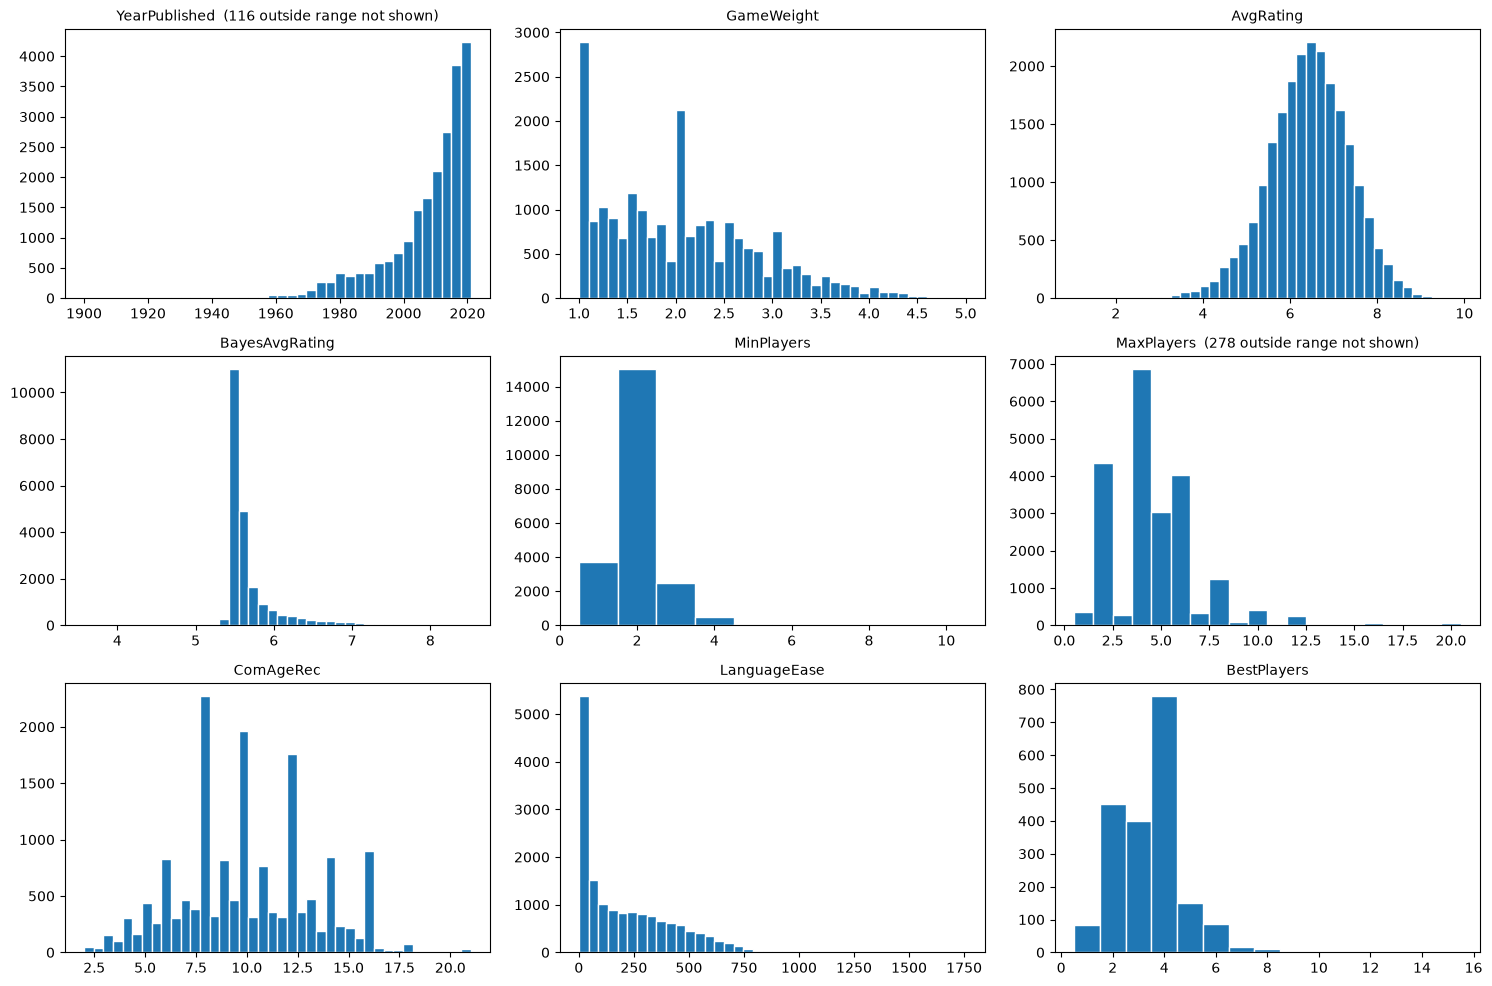

In [ ]:
num = games_lilja.select_dtypes("number").mask(missing)   # zeros become NaN; games_lilja itself is unchanged
display(num.describe().T.round(2))

plot_limits = {"YearPublished": (1900, None), "MaxPlayers": (None, 20)}

fig, axes = plt.subplots(4, 3, figsize=(15, 13))
axes = axes.ravel()

for ax, col in zip(axes, num.columns):
    s = num[col].dropna()
    lo, hi = plot_limits.get(col, (None, None))
    shown = s[(s >= (lo if lo is not None else -np.inf)) & (s <= (hi if hi is not None else np.inf))]

    if pd.api.types.is_integer_dtype(games_lilja[col]) and shown.nunique() <= 40:
        bins = np.arange(shown.min(), shown.max() + 2) - 0.5
    else:
        bins = 40

    ax.hist(shown, bins=bins, edgecolor="white")
    hidden = len(s) - len(shown)
    ax.set_title(col + (f"  ({hidden} outside range not shown)" if hidden else ""), fontsize=10)

for ax in axes[len(num.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Compare metrics with average and Bayesian ratings, including the original view restricted to games with at least 1,000 user ratings.

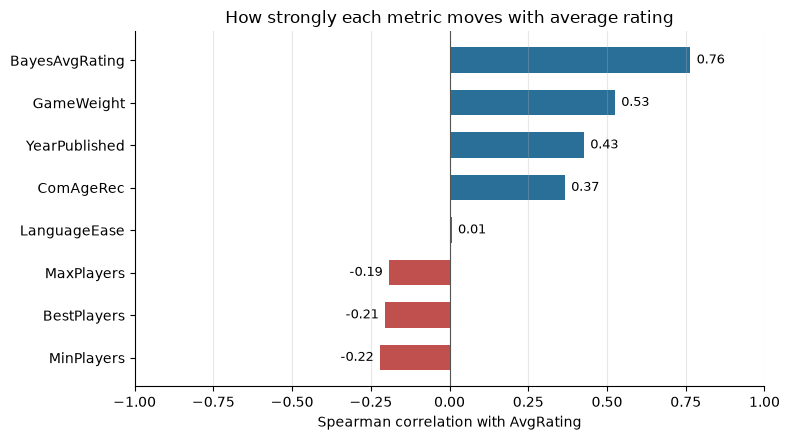

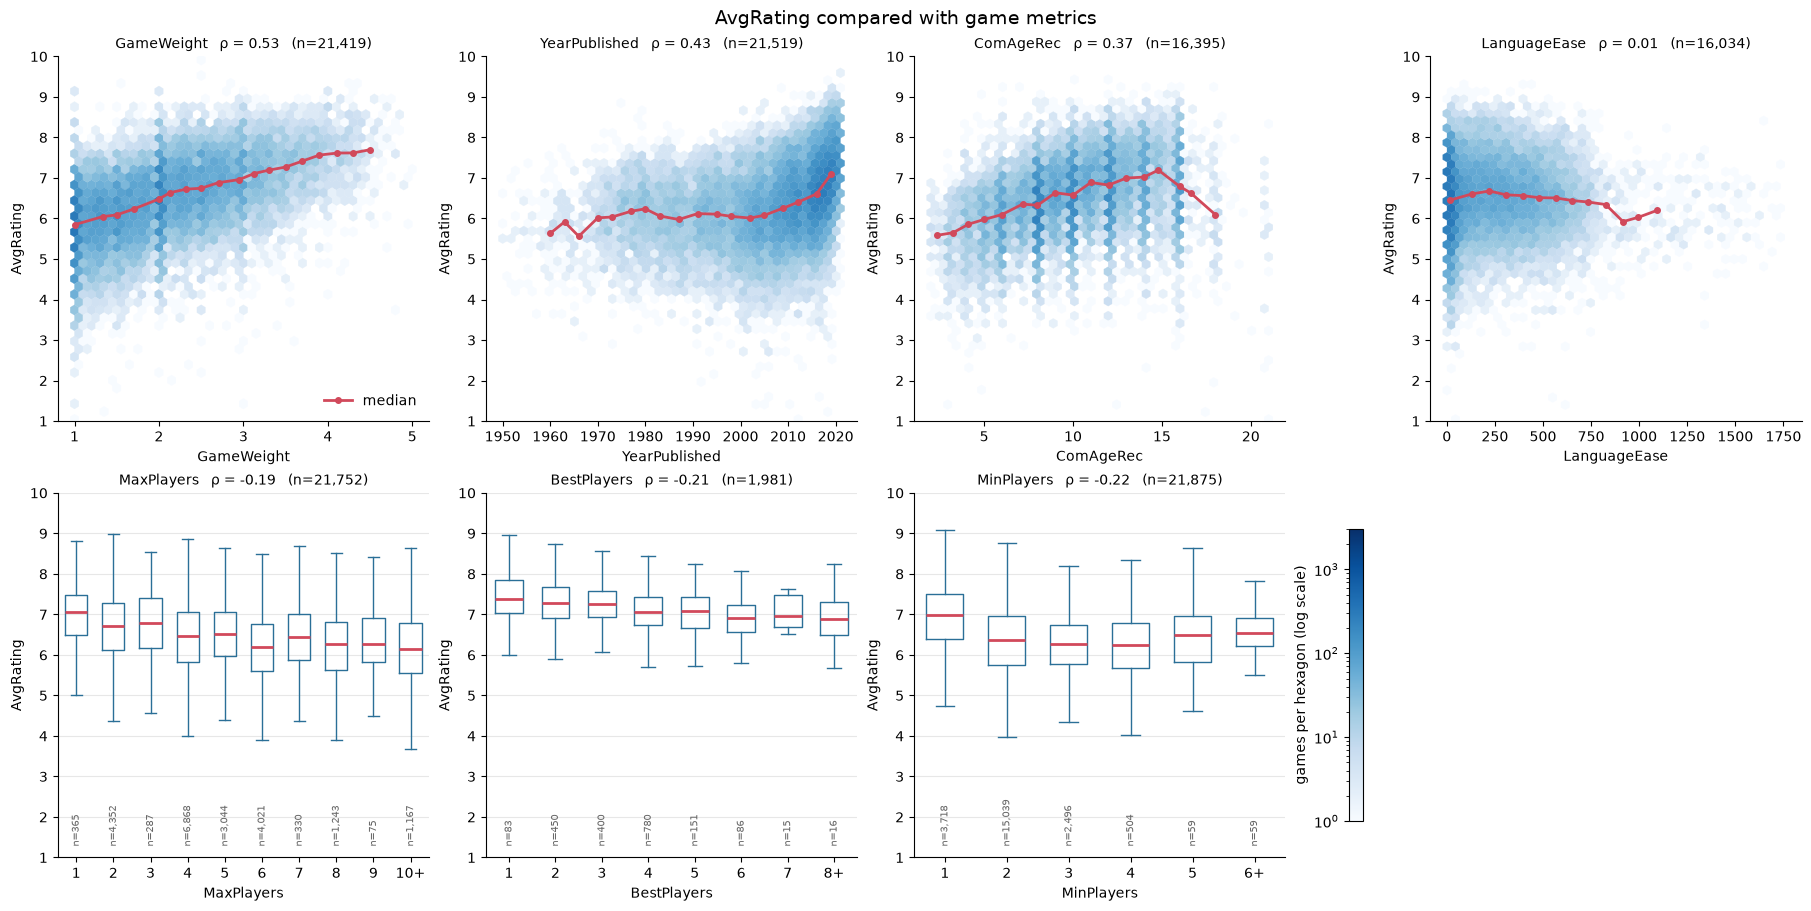

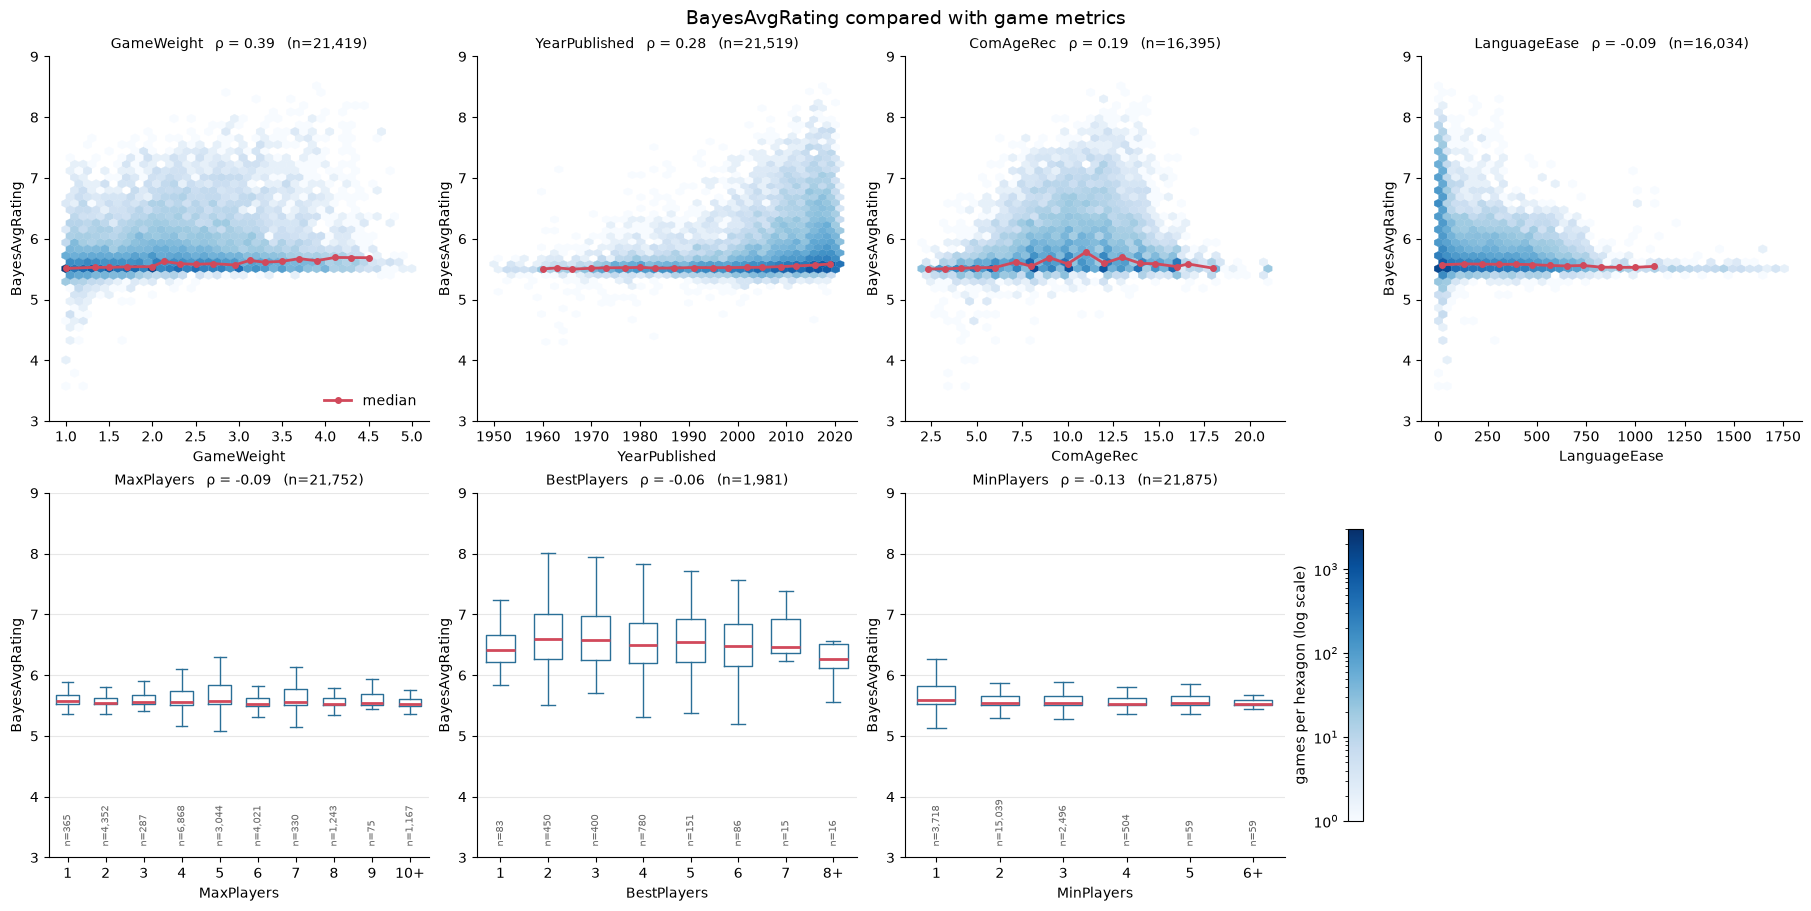

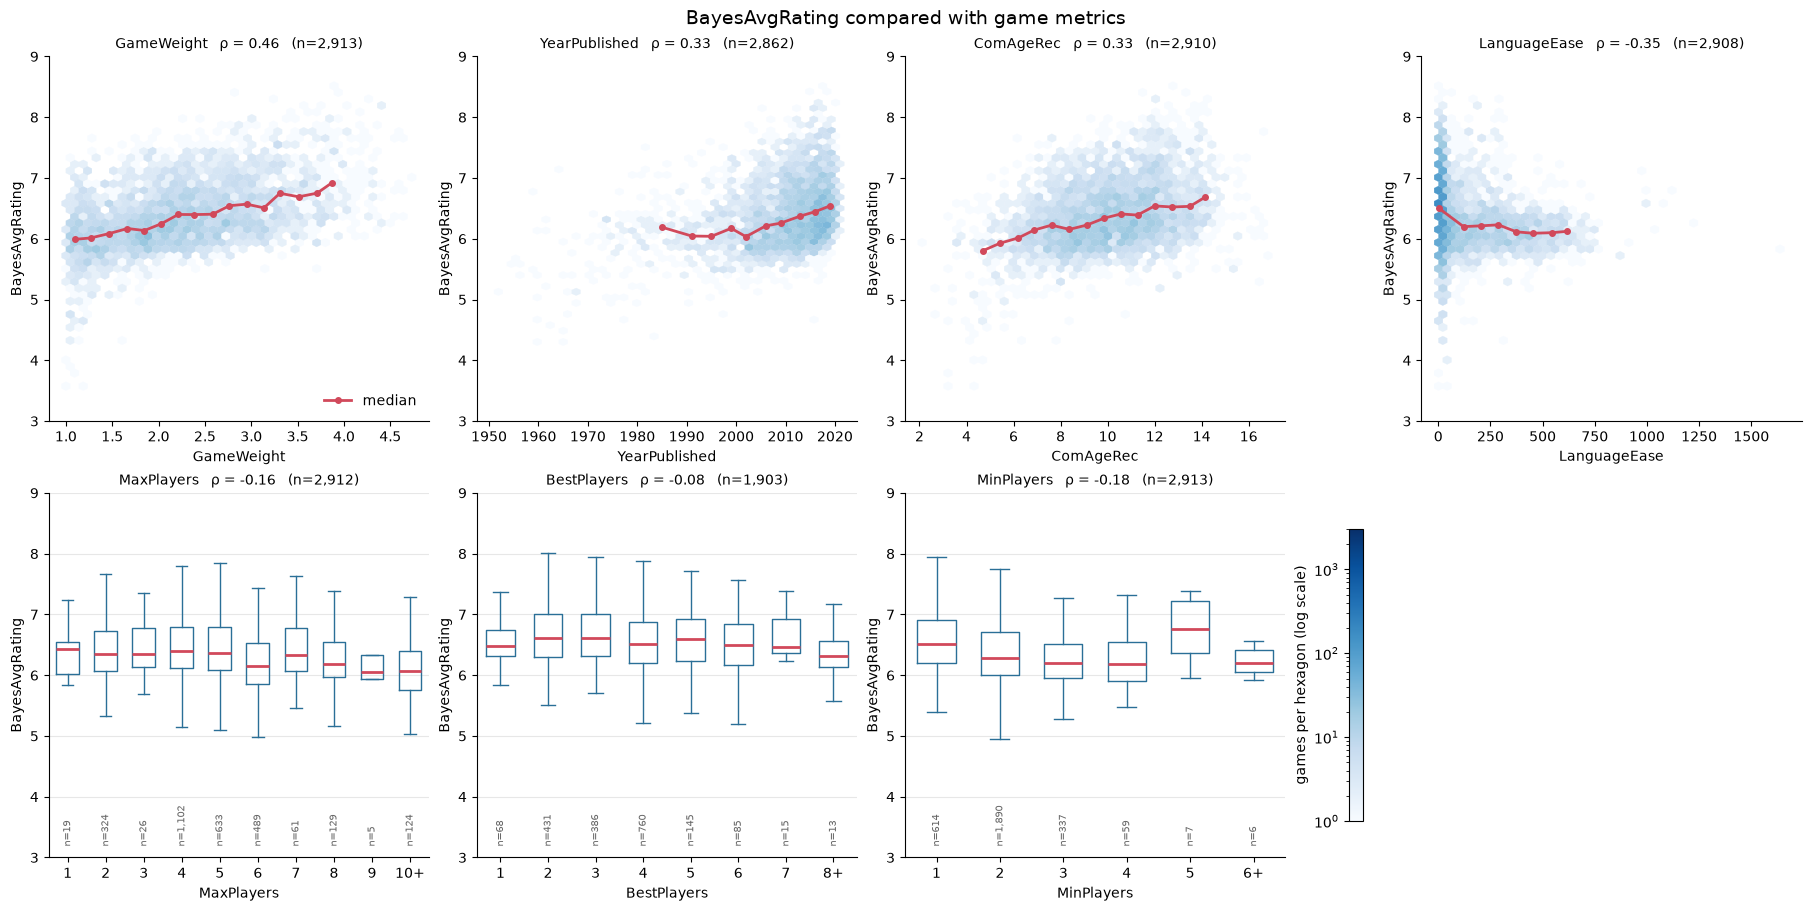

In [ ]:
others = num.drop(columns="AvgRating")
corr = others.corrwith(num["AvgRating"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, "#2a6f97", "#c0504d"), height=0.6)
ax.axvline(0, color="#555", lw=0.8)
for y, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman correlation with AvgRating")
ax.set_title("How strongly each metric moves with average rating")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

plot_against("AvgRating", data=num)
plot_against("BayesAvgRating", data=num)
plot_against("BayesAvgRating", data=num[games["NumUserRatings"] >= 1000])

Compare ratings and popularity between games with and without `BestPlayers`. Missing values and zero placeholders both count as unavailable. The U statistic includes half the tied pairs in the reported probability.

In [ ]:
has_best = ~is_missing(games_lilja["BestPlayers"])          # BestPlayers is stored as 0 when missing
order = ["No BestPlayers", "Has BestPlayers"]
colors = {"No BestPlayers": "#9aa5b1", "Has BestPlayers": "#2a6f97"}

cmp = pd.DataFrame({
    "group": has_best.map({True: "Has BestPlayers", False: "No BestPlayers"}),
    "AvgRating": games_lilja["AvgRating"],
    "NumUserRatings": games["NumUserRatings"],
})

summary = cmp.groupby("group").agg(
    games=("AvgRating", "size"),
    median_rating=("AvgRating", "median"),
    mean_rating=("AvgRating", "mean"),
    median_num_ratings=("NumUserRatings", "median"),
).reindex(order).round(2)
display(summary)

u, p = mannwhitneyu(cmp.loc[has_best, "AvgRating"], cmp.loc[~has_best, "AvgRating"])
print(f"Mann-Whitney U p-value: {p:.2g}")
print(f"Probability of superiority (half credit for ties): {u / (has_best.sum() * (~has_best).sum()):.0%}")

,games,median_rating,mean_rating,median_num_ratings
group,,,,
No BestPlayers,19944,6.37,6.35,104.0
Has BestPlayers,1981,7.16,7.14,3500.0


Mann-Whitney U p-value: 0
Probability of superiority (half credit for ties): 77%


Plot normalised rating distributions and user-rating counts so the very different group sizes remain comparable.

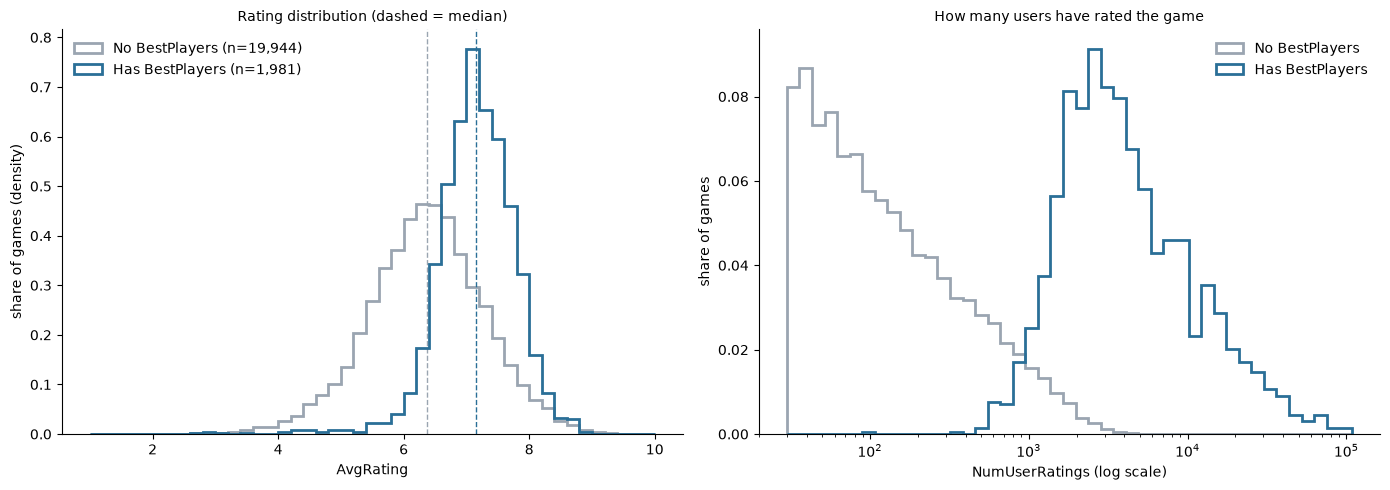

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bins = np.linspace(1, 10, 46)
for g in order:
    axes[0].hist(cmp.loc[cmp.group == g, "AvgRating"], bins=bins, density=True,
                 histtype="step", lw=2, color=colors[g],
                 label=f"{g} (n={summary.loc[g, 'games']:,.0f})")
    axes[0].axvline(summary.loc[g, "median_rating"], color=colors[g], ls="--", lw=1)
axes[0].set_xlabel("AvgRating")
axes[0].set_ylabel("share of games (density)")
axes[0].set_title("Rating distribution (dashed = median)", fontsize=10)
axes[0].legend(frameon=False)

lbins = np.logspace(np.log10(30), np.log10(cmp.NumUserRatings.max()), 46)
for g in order:
    sel = cmp.group == g
    axes[1].hist(cmp.loc[sel, "NumUserRatings"], bins=lbins,
                 weights=np.full(sel.sum(), 1 / sel.sum()),
                 histtype="step", lw=2, color=colors[g], label=g)
axes[1].set_xscale("log")
axes[1].set_xlabel("NumUserRatings (log scale)")
axes[1].set_ylabel("share of games")
axes[1].set_title("How many users have rated the game", fontsize=10)
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Repeat the comparison above several popularity thresholds to assess whether coverage is associated with the number of ratings.

In [ ]:
for t in [1000, 2000, 5000]:
    s = cmp[cmp.NumUserRatings >= t]
    h = s.group == "Has BestPlayers"
    print(f"≥{t:>5} ratings: {len(s):>5} games, {h.mean():.0%} have BestPlayers | "
          f"median rating has={s[h].AvgRating.median():.2f}, no={s[~h].AvgRating.median():.2f}")

≥ 1000 ratings:  2913 games, 65% have BestPlayers | median rating has=7.15, no=6.65
≥ 2000 ratings:  1668 games, 90% have BestPlayers | median rating has=7.17, no=6.69
≥ 5000 ratings:   718 games, 99% have BestPlayers | median rating has=7.27, no=6.90


Measure `GoodPlayers` coverage alongside `BestPlayers` and check how often the two fields are jointly available.

In [ ]:
good_players = games_lilja["GoodPlayers"].map(ast.literal_eval)
has_good = good_players.map(len).gt(0)
player_coverage = pd.DataFrame({
    "BestPlayers available": has_best,
    "GoodPlayers available": has_good,
})
display(player_coverage.agg(["sum", "mean"]).T.rename(columns={"sum": "games", "mean": "share"}))
display(pd.crosstab(player_coverage.iloc[:, 0], player_coverage.iloc[:, 1]))

,games,share
BestPlayers available,1981.0,0.090353
GoodPlayers available,1979.0,0.090262


GoodPlayers available,False,True
BestPlayers available,,
False,19944,0
True,2,1979


### Decision on `BestPlayers`, `GoodPlayers` and `StdDev`

`StdDev` is excluded from the analysis subset and final combined table. `BestPlayers` and `GoodPlayers` are retained for exploration, but both are unavailable for roughly 91% of games. Games with `BestPlayers` also tend to have more user ratings and higher average ratings; the threshold comparisons show why coverage must be considered alongside popularity.

For a baseline model across all games, we recommend excluding both community player fields rather than dropping all games that lack them. They can still support a separate analysis of well-rated games or a model that explicitly handles missingness. The observed group differences do not establish that a preferred player count causes a higher rating.

Inspect the coverage, range and upper tail of `LanguageEase`. The supplied documentation labels it “Language requirement” but does not define its scale or direction.

,LanguageEase
count,16034.000000
mean,216.461819
std,236.595136
min,1.000000
25%,24.027778
50%,138.000000
75%,351.000000
90%,536.000000
95%,638.000000
99%,1028.340000


Missing LanguageEase: 5,891 (26.9%)


,Name,LanguageEase,AvgRating,GameWeight,NumUserRatings
4259,Pole Position,1757.000000,6.22844,1.6923,122
4254,DeltaVee,1737.500000,5.54605,3.1000,76
4252,Mississippi Banzai,1733.000000,6.80086,2.1111,58
4243,Nomad Gods,1718.000000,7.32756,2.8571,45
4239,The 80's Game,1704.000000,5.17387,1.7778,111
4235,"Dark Ages: Tactical Warfare, 500-1300",1693.000000,6.06977,2.5833,43
4231,NATO: Operational Combat in Europe in the 1970's,1682.500000,6.19134,2.7895,127
4228,1844: Schweiz,1666.333333,8.35801,4.3158,195
4227,Imperial Governor & Strategos,1664.000000,6.82000,2.2000,65
4225,Dungeons & Dragons Miniatures,1658.363636,6.54616,2.5667,1074


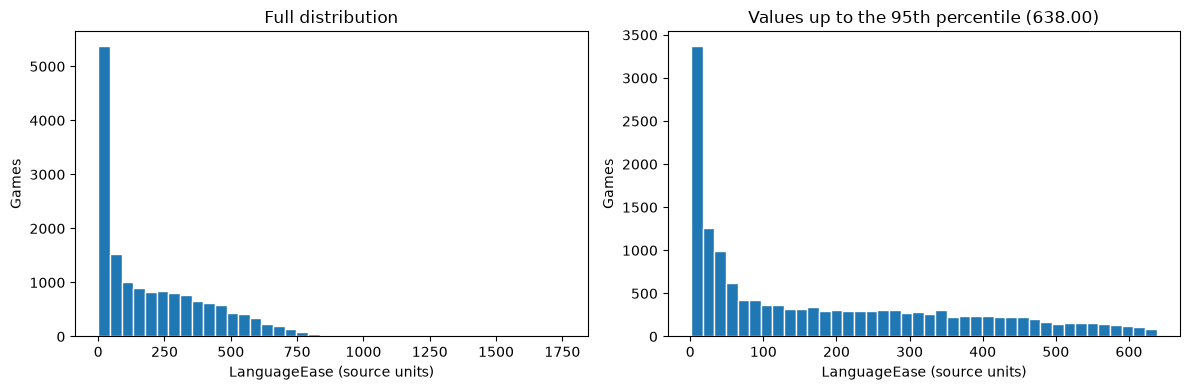

In [ ]:
language_data = games[["Name", "LanguageEase", "AvgRating", "GameWeight", "NumUserRatings"]].copy()
language_data["LanguageEase"] = language_data["LanguageEase"].mask(is_missing(language_data["LanguageEase"]))
language_values = language_data["LanguageEase"].dropna()
display(language_values.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).to_frame())
print(f"Missing LanguageEase: {language_data.LanguageEase.isna().sum():,} ({language_data.LanguageEase.isna().mean():.1%})")
display(language_data.nlargest(10, "LanguageEase"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(language_values, bins=40, edgecolor="white")
axes[0].set(xlabel="LanguageEase (source units)", ylabel="Games", title="Full distribution")
upper = language_values.quantile(0.95)
axes[1].hist(language_values[language_values <= upper], bins=40, edgecolor="white")
axes[1].set(xlabel="LanguageEase (source units)", ylabel="Games", title=f"Values up to the 95th percentile ({upper:.2f})")
plt.tight_layout()
plt.show()

Check whether language-score coverage is associated with ratings and popularity, then inspect its observed associations with rating and complexity.

,games,mean_rating,median_num_ratings
LanguageEase available,,,
False,5891,6.22,59.0
True,16034,6.50,192.0


,LanguageEase,AvgRating,GameWeight,NumUserRatings
LanguageEase,1.000,0.007,-0.035,-0.176
AvgRating,0.007,1.000,0.505,0.259
GameWeight,-0.035,0.505,1.000,0.186
NumUserRatings,-0.176,0.259,0.186,1.000


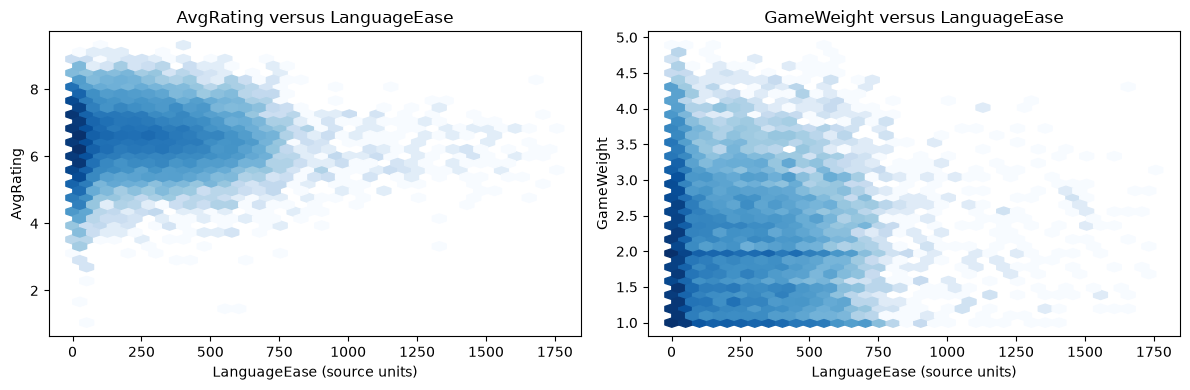

In [ ]:
language_data["LanguageEase available"] = language_data["LanguageEase"].notna()
display(language_data.groupby("LanguageEase available").agg(
    games=("AvgRating", "size"),
    mean_rating=("AvgRating", "mean"),
    median_num_ratings=("NumUserRatings", "median"),
).round(2))
display(language_data[["LanguageEase", "AvgRating", "GameWeight", "NumUserRatings"]].corr(method="spearman").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, ["AvgRating", "GameWeight"]):
    d = language_data[["LanguageEase", target]].dropna()
    d = d[d[target] > 0]
    ax.hexbin(d.LanguageEase, d[target], gridsize=35, mincnt=1, bins="log", cmap="Blues")
    ax.set(xlabel="LanguageEase (source units)", ylabel=target, title=f"{target} versus LanguageEase")
plt.tight_layout()
plt.show()

The large language-score range and the undefined scale make its meaning uncertain. Keep the original values for inspection, treat the correlations as exploratory, and verify the source encoding before using this field as a measure of language ease or dependence. No values are silently clipped or imputed.

Show the original Spearman correlation overview, including the number of user ratings.

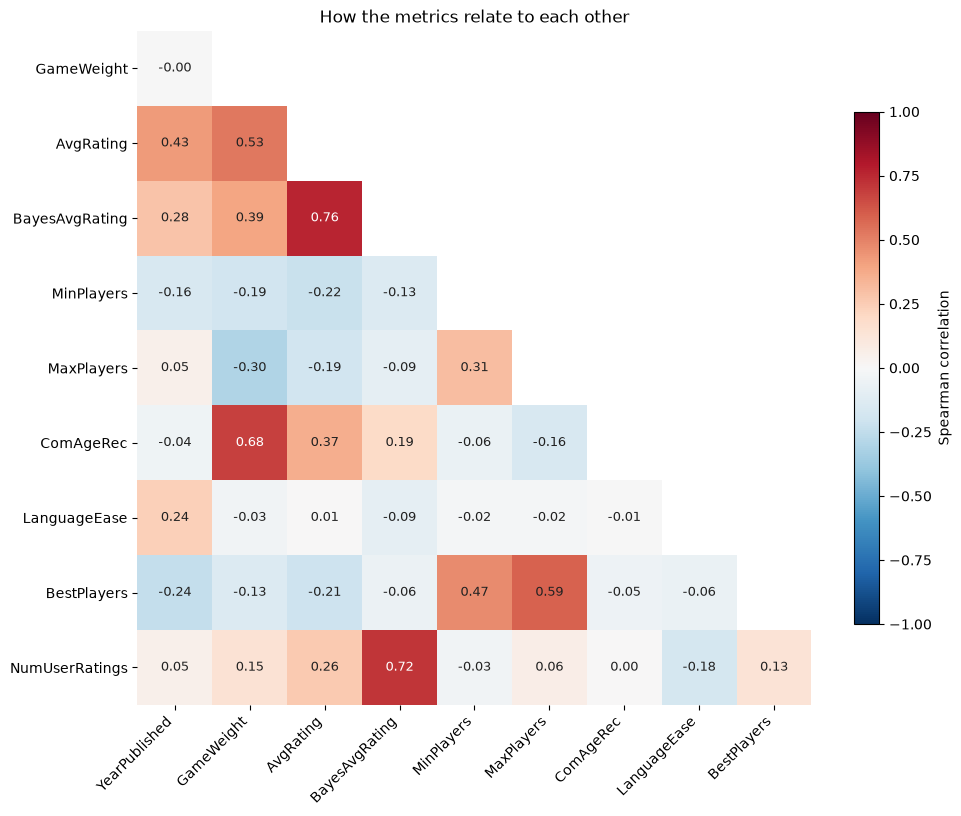

In [ ]:
metrics = num.join(games["NumUserRatings"])
corr = metrics.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the duplicate upper half and the diagonal

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.where(~mask), cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "#222")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.set_xlim(-0.5, len(corr) - 1.5)
ax.set_ylim(len(corr) - 0.5, 0.5)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("How the metrics relate to each other")
plt.tight_layout()
plt.show()

Inspect complexity versus recommended age and publication year versus popularity with the original median-trend plots.

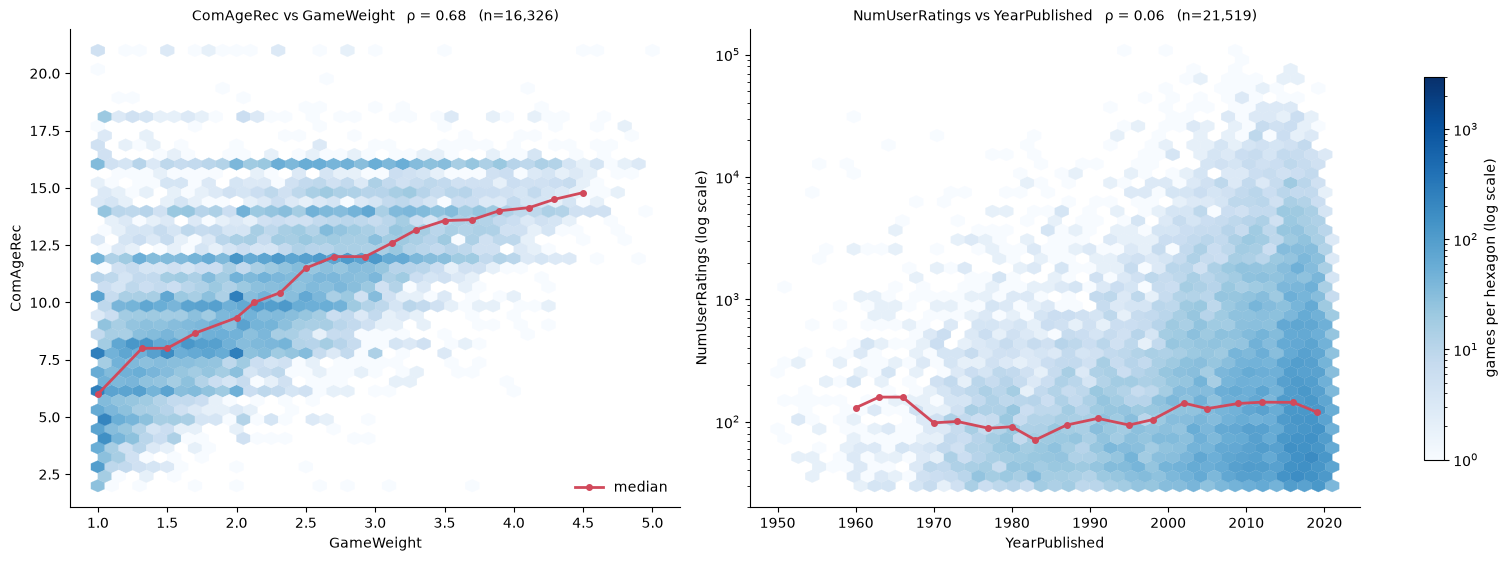

In [ ]:
RED = "#d1495b"

def pair_plot(ax, x, y, data=metrics, xlim=None, logy=False):
    d = data[[x, y]].dropna()
    if xlim:
        d = d[d[x].between(*xlim)]
    rho = d[x].corr(d[y], method="spearman")
    hb = ax.hexbin(d[x], d[y], gridsize=40, cmap="Blues", mincnt=1, norm=LogNorm(1, 3000),
                   yscale="log" if logy else "linear", linewidths=0.2)

    g = d.groupby(pd.cut(d[x], 20), observed=True)
    trend = g.agg(x=(x, "median"), y=(y, "median"), n=(y, "size")).query("n >= 30")
    ax.plot(trend.x, trend.y, color=RED, lw=2, marker="o", ms=4, label="median")

    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(x)
    ax.set_ylabel(y + (" (log scale)" if logy else ""))
    ax.set_title(f"{y} vs {x}   ρ = {rho:.2f}   (n={len(d):,})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    return hb

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
pair_plot(axes[0], "GameWeight", "ComAgeRec")
hb = pair_plot(axes[1], "YearPublished", "NumUserRatings", xlim=(1950, 2021), logy=True)
axes[0].legend(loc="lower right", frameon=False)
fig.colorbar(hb, ax=axes, shrink=0.8, label="games per hexagon (log scale)")
plt.show()

## Cornelius — columns 14–26: popularity, playtime and counts

Review the count fields and playtime columns. Here, zero can be a genuine count, so it is reported separately from missing values.

In [ ]:
cornelius_cols = [
    "NumOwned", "NumWant", "NumWish", "NumWeightVotes", "MfgPlaytime",
    "ComMinPlaytime", "ComMaxPlaytime", "MfgAgeRec", "NumUserRatings",
    "NumComments", "NumAlternates", "NumExpansions",
]
games_cornelius = games[cornelius_cols].copy()
overview = pd.DataFrame({
    "dtype": games_cornelius.dtypes,
    "missing": games_cornelius.isna().sum(),
    "zero": games_cornelius.eq(0).sum(),
    "unique_values": games_cornelius.nunique(),
})
display(overview)
display(games_cornelius.describe().T.round(2))

,dtype,missing,zero,unique_values
NumOwned,int64,0,1,4262
NumWant,int64,0,1938,699
NumWish,int64,0,106,1798
NumWeightVotes,int64,0,506,775
MfgPlaytime,int64,0,780,121
ComMinPlaytime,int64,0,652,90
ComMaxPlaytime,int64,0,780,121
MfgAgeRec,int64,0,1325,21
NumUserRatings,int64,0,0,3130
NumComments,int64,0,21925,1


,count,mean,std,min,25%,50%,75%,max
NumOwned,21925.0,1467.85,5294.12,0.0,150.0,320.0,899.0,166497.0
NumWant,21925.0,41.69,117.26,0.0,3.0,9.0,28.0,2031.0
NumWish,21925.0,228.46,788.48,0.0,14.0,39.0,127.0,19182.0
NumWeightVotes,21925.0,49.48,205.76,0.0,4.0,9.0,26.0,7673.0
MfgPlaytime,21925.0,90.51,529.66,0.0,25.0,45.0,90.0,60000.0
ComMinPlaytime,21925.0,63.68,443.92,0.0,20.0,30.0,60.0,60000.0
ComMaxPlaytime,21925.0,90.51,529.66,0.0,25.0,45.0,90.0,60000.0
MfgAgeRec,21925.0,9.61,3.64,0.0,8.0,10.0,12.0,25.0
NumUserRatings,21925.0,861.67,3638.68,30.0,56.0,123.0,395.0,108101.0
NumComments,21925.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0


Check the community playtime fields against the manufacturer field and verify whether `NumComments` contains useful variation.

In [ ]:
playtime_cols = ["MfgPlaytime", "ComMinPlaytime", "ComMaxPlaytime"]
display(games_cornelius[playtime_cols].describe().T.round(2))
print(f"Manufacturer time equals community maximum: {games_cornelius.MfgPlaytime.eq(games_cornelius.ComMaxPlaytime).mean():.1%}")
display(games_cornelius["NumComments"].value_counts(dropna=False).rename("games").to_frame())

,count,mean,std,min,25%,50%,75%,max
MfgPlaytime,21925.0,90.51,529.66,0.0,25.0,45.0,90.0,60000.0
ComMinPlaytime,21925.0,63.68,443.92,0.0,20.0,30.0,60.0,60000.0
ComMaxPlaytime,21925.0,90.51,529.66,0.0,25.0,45.0,90.0,60000.0


Manufacturer time equals community maximum: 100.0%


,games
NumComments,
0,21925


### Playtime and comments decisions

Remove `ComMinPlaytime` and `ComMaxPlaytime` and retain manufacturer information. This source provides a single manufacturer duration, `MfgPlaytime`, rather than separate manufacturer minimum and maximum columns; no new bounds are inferred. The community player fields in Lilja’s section are a separate decision.

`NumComments` is zero throughout this source, so it contributes no variation and is removed from the working subset and final export. These zeros are reported as unavailable comment information, rather than evidence that the games have never received comments.

Apply the playtime and comments decisions, then compare the retained fields with average rating. Zero duration and age placeholders are masked for this analysis; genuine zero counts remain.

,Spearman correlation with AvgRating
NumAlternates,-0.043
NumWeightVotes,0.221
NumUserRatings,0.259
NumOwned,0.289
NumExpansions,0.333
MfgAgeRec,0.346
MfgPlaytime,0.370
NumWant,0.589
NumWish,0.597


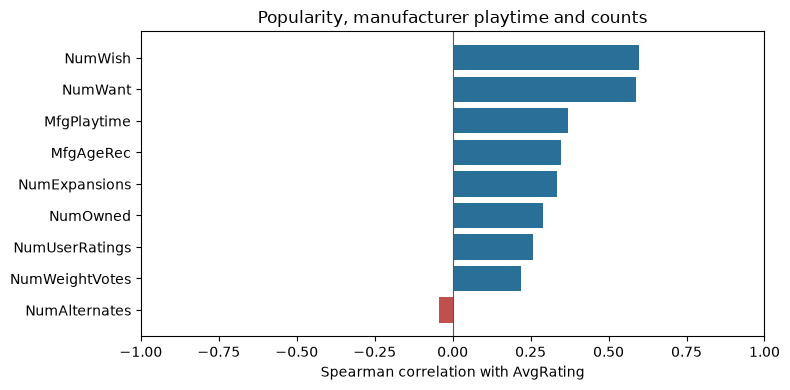

In [ ]:
games_cornelius = games_cornelius.drop(columns=["ComMinPlaytime", "ComMaxPlaytime", "NumComments"])
cornelius_metrics = games_cornelius.copy()
for col in ["MfgPlaytime", "MfgAgeRec"]:
    cornelius_metrics[col] = cornelius_metrics[col].mask(is_missing(cornelius_metrics[col]))
cornelius_metrics["AvgRating"] = games["AvgRating"]
corr = cornelius_metrics.drop(columns="AvgRating").corrwith(cornelius_metrics["AvgRating"], method="spearman").sort_values()
display(corr.rename("Spearman correlation with AvgRating").to_frame().round(3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, "#2a6f97", "#c0504d"))
ax.axvline(0, color="#555", lw=0.8)
ax.set(xlim=(-1, 1), xlabel="Spearman correlation with AvgRating", title="Popularity, manufacturer playtime and counts")
plt.tight_layout()
plt.show()

## Pietro — columns 27–38: implementations, family and Kickstarter

Keep Pietro’s non-rank fields and remove `ImagePath` and all ranks from this subset. Names, publication years and ratings provide context for the retained analysis.

In [ ]:
pietro_cols = ["NumImplementations", "IsReimplementation", "Family", "Kickstarted"]
games_pietro = games[["BGGId", "Name", "YearPublished", "AvgRating"] + pietro_cols].copy()
display(games_pietro.head(10))

,BGGId,Name,YearPublished,AvgRating,NumImplementations,IsReimplementation,Family,Kickstarted
0,1,Die Macher,1986,7.61428,0,0,Classic Line (Valley Games),0
1,2,Dragonmaster,1981,6.64537,2,1,NaN,0
2,3,Samurai,1998,7.45601,1,0,Euro Classics (Reiner Knizia),0
3,4,Tal der Könige,1992,6.60006,0,0,NaN,0
4,5,Acquire,1964,7.33861,0,0,3M Bookshelf,0
5,6,Mare Mediterraneum,1989,6.55370,0,0,NaN,0
6,7,Cathedral,1978,6.52083,0,0,NaN,0
7,8,Lords of Creation,1993,6.10716,0,0,NaN,0
8,9,El Caballero,1998,6.45265,0,0,El Grand,0
9,10,Elfenland,1998,6.69695,3,1,Elfenroads,0


Summarise missing values and unique values for the retained fields.

In [ ]:
overview = pd.DataFrame({
    "dtype": games_pietro.dtypes.astype(str),
    "non-null": games_pietro.notna().sum(),
    "missing": games_pietro.isna().sum(),
    "missing %": (games_pietro.isna().mean() * 100).round(1),
    "unique": games_pietro.nunique(),
})
overview

,dtype,non-null,missing,missing %,unique
BGGId,int64,21925,0,0.0,21925
Name,str,21925,0,0.0,21521
YearPublished,int64,21925,0,0.0,188
AvgRating,float64,21925,0,0.0,20489
NumImplementations,int64,21925,0,0.0,23
IsReimplementation,int64,21925,0,0.0,2
Family,str,6663,15262,69.6,1456
Kickstarted,int64,21925,0,0.0,2


Show the statistical summary of Pietro’s retained subset.

In [ ]:
games_pietro.describe(include="all").T[["count", "unique", "mean", "std", "min", "50%", "max"]].round(2)

,count,unique,mean,std,min,50%,max
BGGId,21925.0,NaN,117652.663216,104628.721777,1.0,105305.0,349161.0
Name,21925,21521,NaN,NaN,NaN,NaN,NaN
YearPublished,21925.0,NaN,1985.494914,212.486214,-3500.0,2011.0,2021.0
AvgRating,21925.0,NaN,6.424922,0.932477,1.04133,6.45395,9.91429
NumImplementations,21925.0,NaN,0.308734,0.848095,0.0,0.0,38.0
IsReimplementation,21925.0,NaN,0.116762,0.321143,0.0,0.0,1.0
Family,6663,1456,NaN,NaN,NaN,NaN,NaN
Kickstarted,21925.0,NaN,0.153341,0.360324,0.0,0.0,1.0


Plot the number of implementations, including a logarithmic view of the long tail. Zero implementations is a valid count.

count    21925.00
mean         0.31
std          0.85
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         38.00


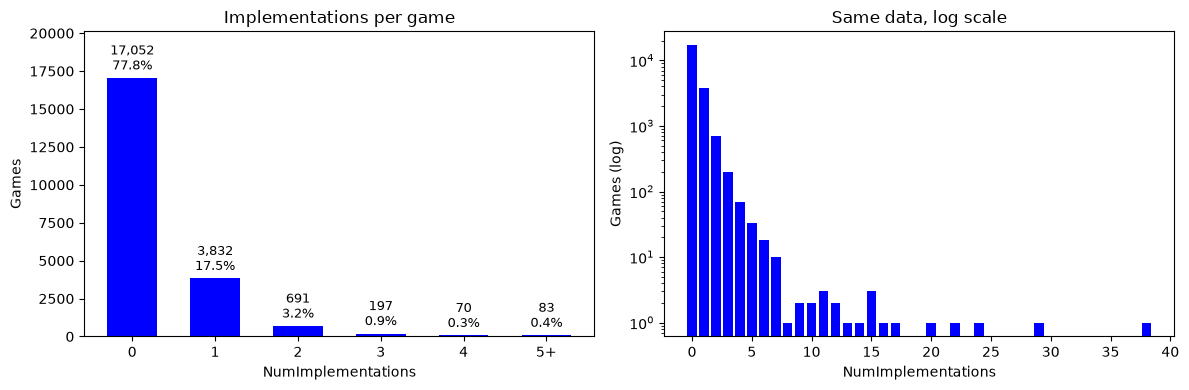

In [ ]:
n = games_pietro["NumImplementations"]
print(n.describe().round(2).to_string())

counts = n.clip(upper=5).value_counts().sort_index()
labels = [str(i) for i in counts.index[:-1]] + ["5+"]
full = n.value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
bars = ax1.bar(labels, counts.values, color="blue", width=0.6)
ax1.bar_label(bars, labels=[f"{v:,}\n{v / len(n):.1%}" for v in counts.values],
              padding=3, fontsize=9)
ax1.set(title="Implementations per game", xlabel="NumImplementations", ylabel="Games")
ax1.set_ylim(0, counts.max() * 1.18)
ax1.grid(axis="x", visible=False)

ax2.bar(full.index, full.values, color="blue", width=0.8)
ax2.set_yscale("log")
ax2.set(title="Same data, log scale", xlabel="NumImplementations", ylabel="Games (log)")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

List the ten games with the most implementations. Average rating replaces the removed rank column in this table.

In [ ]:
games_pietro.nlargest(10, "NumImplementations")[["Name", "YearPublished", "NumImplementations", "AvgRating"]]

,Name,YearPublished,NumImplementations,AvgRating
221,Fluxx,1997,38,5.67195
12,Catan,1995,29,7.13746
1401,Munchkin,2001,24,5.89145
967,Clue,1949,22,5.66992
159,Risk,1959,20,5.59396
673,Carcassonne,2000,17,7.41883
10482,Quarriors!,2011,16,6.75252
1051,Monopoly,1933,15,4.37412
11807,Love Letter,2012,15,7.23317
12068,ZnajZnak,2012,15,6.34896


Compare original games with reimplementations using Pietro’s original count summary.

In [ ]:
r = games_pietro["IsReimplementation"]
print(r.value_counts().rename({0: "original", 1: "reimplementation"}).to_frame("games").assign(share=lambda x: (x.games / len(r)).map("{:.1%}".format)))

                    games  share
IsReimplementation              
original            19365  88.3%
reimplementation     2560  11.7%


Inspect missing family information, the largest families and the distribution of family sizes.

Missing family: 15,262 games (69.6%)
Games with a family: 6,663 in 1,456 different families
Families with a single game: 402 (27.6% of families)


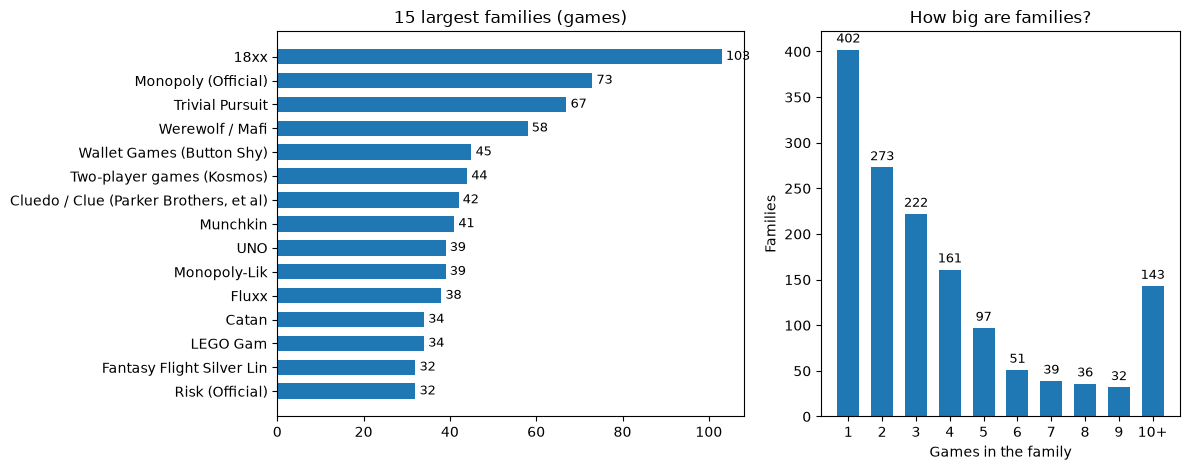

In [ ]:
fam = games_pietro["Family"]
fam_counts = fam.value_counts()
print(f"Missing family: {fam.isna().sum():,} games ({fam.isna().mean():.1%})")
print(f"Games with a family: {fam.notna().sum():,} in {fam.nunique():,} different families")
print(f"Families with a single game: {(fam_counts == 1).sum():,} ({(fam_counts == 1).mean():.1%} of families)")

top = fam_counts.head(15).iloc[::-1]
sizes = fam_counts.clip(upper=10).value_counts().sort_index()
size_labels = [str(i) for i in sizes.index[:-1]] + ["10+"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
bars = ax1.barh(top.index, top.values, height=0.65)
ax1.bar_label(bars, padding=3, fontsize=9)
ax1.set(title="15 largest families (games)")
ax1.grid(axis="y", visible=False)

bars = ax2.bar(size_labels, sizes.values, width=0.65)
ax2.bar_label(bars, padding=3, fontsize=9)
ax2.set(title="How big are families?", xlabel="Games in the family", ylabel="Families")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Show the share of Kickstarted games and its relationship with publication year.

Kickstarted games: 3,362 of 21,925 (15.3%)


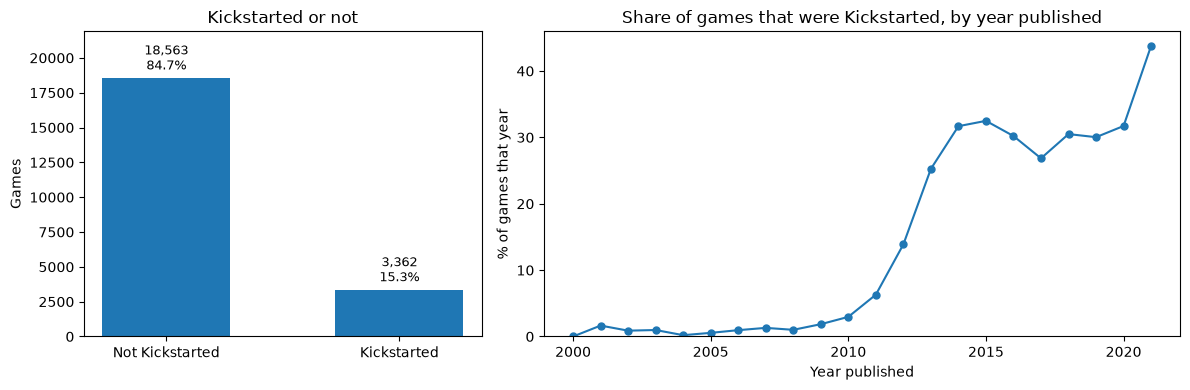

YearPublished,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
share,0.0,0.016,0.009,0.01,0.002,0.005,0.01,0.013,0.01,0.019,...,0.139,0.253,0.317,0.325,0.302,0.268,0.305,0.3,0.317,0.438
games,303.0,304.000,341.000,410.00,501.000,547.000,524.00,539.000,597.00,647.000,...,843.000,875.000,1032.000,1185.000,1321.000,1356.000,1351.000,1302.0,927.000,660.000


In [ ]:
k = games_pietro["Kickstarted"]
print(f"Kickstarted games: {k.sum():,} of {len(k):,} ({k.mean():.1%})")

by_year = (games_pietro[games_pietro["YearPublished"].between(2000, 2021)]
           .groupby("YearPublished")["Kickstarted"].agg(share="mean", games="size"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})
kc = k.value_counts().sort_index()
bars = ax1.bar(["Not Kickstarted", "Kickstarted"], kc.values, width=0.55)
ax1.bar_label(bars, labels=[f"{v:,}\n{v / len(k):.1%}" for v in kc.values], padding=3, fontsize=9)
ax1.set(title="Kickstarted or not", ylabel="Games")
ax1.set_ylim(0, kc.max() * 1.18)
ax1.grid(axis="x", visible=False)

ax2.plot(by_year.index, by_year["share"] * 100, marker="o", markersize=5)
ax2.set(title="Share of games that were Kickstarted, by year published", xlabel="Year published", ylabel="% of games that year")
ax2.set_ylim(0, None)
plt.tight_layout()
plt.show()
by_year.T.round(3)

`ImagePath` and every rank column are excluded from the final combined table. The implementation, reimplementation, family and Kickstarter analyses are retained from Pietro’s notebook.

## Kristoffer — categories: coverage, rating associations and overlap

Select the category indicators by name so ranks cannot enter the subset. Keep every game, including those with no recorded category.

In [ ]:
category_cols = [col for col in games.columns if col.startswith("Cat:")]
games_kristoffer = games[["BGGId", "Name"] + category_cols].copy()
print("Total rows:", games_kristoffer.shape[0])
display(games_kristoffer[category_cols].sum().rename("games").to_frame())
print("Total category memberships:", games_kristoffer[category_cols].sum().sum())
display(games_kristoffer.head(20))

Total rows: 21925


,games
Cat:Thematic,1224
Cat:Strategy,2319
Cat:War,3530
Cat:Family,2316
Cat:CGS,303
Cat:Abstract,1115
Cat:Party,640
Cat:Childrens,881


Total category memberships: 12328


,BGGId,Name,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,1,Die Macher,0,1,0,0,0,0,0,0
1,2,Dragonmaster,0,1,0,0,0,0,0,0
2,3,Samurai,0,1,0,0,0,0,0,0
3,4,Tal der Könige,0,0,0,0,0,0,0,0
4,5,Acquire,0,1,0,0,0,0,0,0
5,6,Mare Mediterraneum,0,0,0,0,0,0,0,0
6,7,Cathedral,0,0,0,0,0,1,0,0
7,8,Lords of Creation,0,0,0,0,0,0,0,0
8,9,El Caballero,0,1,0,0,0,0,0,0
9,10,Elfenland,0,0,0,1,0,0,0,0


Add average rating and inspect category coverage. The indicators can overlap, and a row of zeros means no category is recorded in these fields.

,Missing values
BGGId,0
Name,0
Cat:Thematic,0
Cat:Strategy,0
Cat:War,0
Cat:Family,0
Cat:CGS,0
Cat:Abstract,0
Cat:Party,0
Cat:Childrens,0


,AvgRating
count,21925.000000
mean,6.424922
std,0.932477
min,1.041330
25%,5.836960
50%,6.453950
75%,7.052450
max,9.914290


Games with no category: 11184
Games in multiple categories: 1574


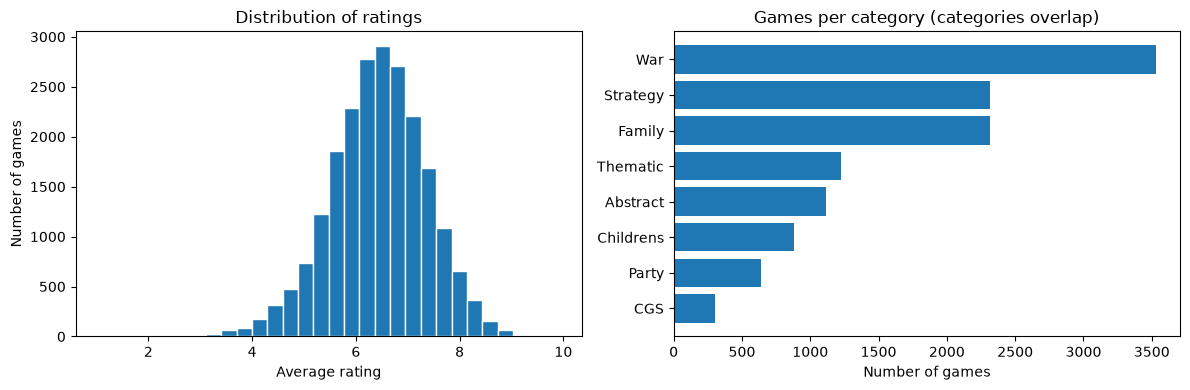

In [ ]:
games_kristoffer = games_kristoffer.copy()
games_kristoffer["AvgRating"] = pd.to_numeric(games.loc[games_kristoffer.index, "AvgRating"], errors="coerce")
category_cols = [col for col in games_kristoffer.columns if col.startswith("Cat:")]

display(games_kristoffer.isna().sum().rename("Missing values").to_frame())
display(games_kristoffer["AvgRating"].describe().to_frame())
category_counts = games_kristoffer[category_cols].sum().sort_values()
print("Games with no category:", (games_kristoffer[category_cols].sum(axis=1) == 0).sum())
print("Games in multiple categories:", (games_kristoffer[category_cols].sum(axis=1) > 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(games_kristoffer["AvgRating"].dropna(), bins=30, edgecolor="white")
axes[0].set(xlabel="Average rating", ylabel="Number of games", title="Distribution of ratings")
axes[1].barh(category_counts.index.str.replace("Cat:", "", regex=False), category_counts)
axes[1].set(xlabel="Number of games", title="Games per category (categories overlap)")
plt.tight_layout()
plt.show()

Compare games inside and outside each category. The overall baseline includes every game once, including uncategorised games.

,Games with rating,Mean rating (present),Mean rating (absent),Median rating (present),Mean difference,Mean minus all games,Correlation with rating
Category,,,,,,,
Childrens,881,5.528,6.462,5.567,-0.935,-0.897,-0.197
Abstract,1115,6.237,6.435,6.261,-0.198,-0.188,-0.047
Party,640,6.291,6.429,6.342,-0.138,-0.134,-0.025
CGS,303,6.398,6.425,6.452,-0.027,-0.027,-0.003
Family,2316,6.424,6.425,6.452,-0.001,-0.001,-0.000
Thematic,1224,6.805,6.402,6.812,0.402,0.380,0.099
War,3530,6.880,6.338,6.891,0.543,0.455,0.214
Strategy,2319,6.954,6.362,6.958,0.592,0.529,0.195


/var/folders/jb/6c64cyn54ldchn68phtz2glr0000gn/T/ipykernel_72342/2327044578.py:24: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = axes[0].boxplot(groups, vert=False, showfliers=False, patch_artist=True)


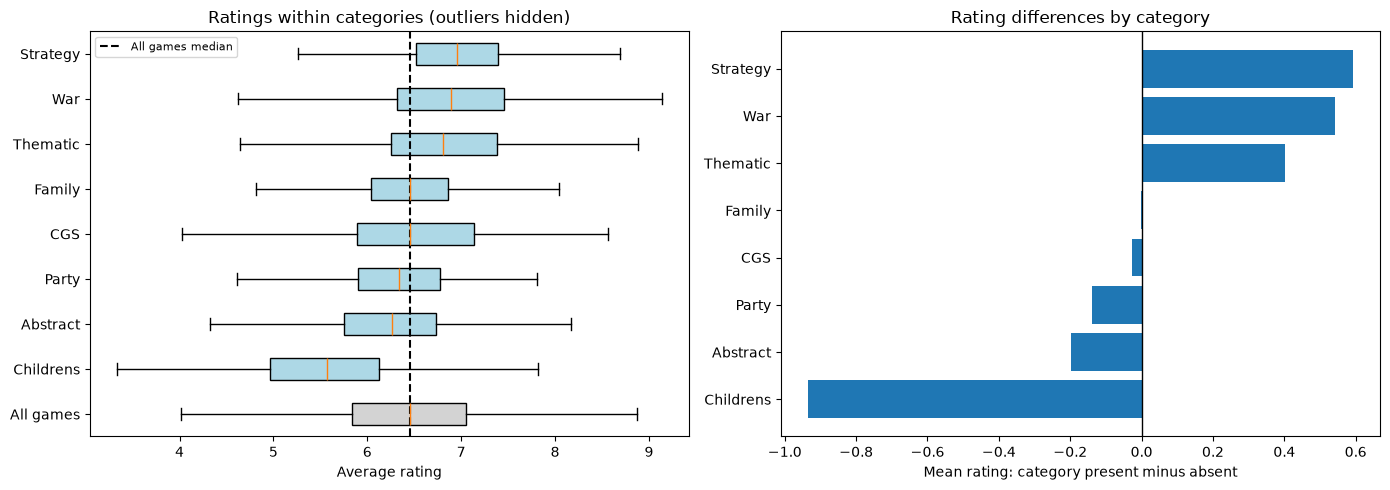

In [ ]:
baseline = games_kristoffer["AvgRating"].dropna()
rows = []
for col in category_cols:
    present = games_kristoffer.loc[games_kristoffer[col] == 1, "AvgRating"].dropna()
    absent = games_kristoffer.loc[games_kristoffer[col] == 0, "AvgRating"].dropna()
    rows.append({
        "Category": col.replace("Cat:", ""),
        "Games with rating": len(present),
        "Mean rating (present)": present.mean(),
        "Mean rating (absent)": absent.mean(),
        "Median rating (present)": present.median(),
        "Mean difference": present.mean() - absent.mean(),
        "Mean minus all games": present.mean() - baseline.mean(),
        "Correlation with rating": games_kristoffer[col].corr(games_kristoffer["AvgRating"]),
    })

category_summary = pd.DataFrame(rows).set_index("Category").sort_values("Mean difference")
display(category_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordered_cols = ["Cat:" + name for name in category_summary.index]
groups = [games_kristoffer.loc[games_kristoffer[col] == 1, "AvgRating"].dropna() for col in ordered_cols]
groups = [baseline] + groups
boxes = axes[0].boxplot(groups, vert=False, showfliers=False, patch_artist=True)
for i, box in enumerate(boxes["boxes"]):
    box.set_facecolor("lightgray" if i == 0 else "lightblue")
axes[0].set_yticks(range(1, len(groups) + 1), ["All games"] + list(category_summary.index))
axes[0].axvline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[0].legend(fontsize=8)
axes[0].set(xlabel="Average rating", title="Ratings within categories (outliers hidden)")
axes[1].barh(category_summary.index, category_summary["Mean difference"])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(xlabel="Mean rating: category present minus absent", title="Rating differences by category")
plt.tight_layout()
plt.show()

Calculate category-to-category correlations and their associations with rating. Pearson correlation between a binary indicator and a rating is the point-biserial correlation.

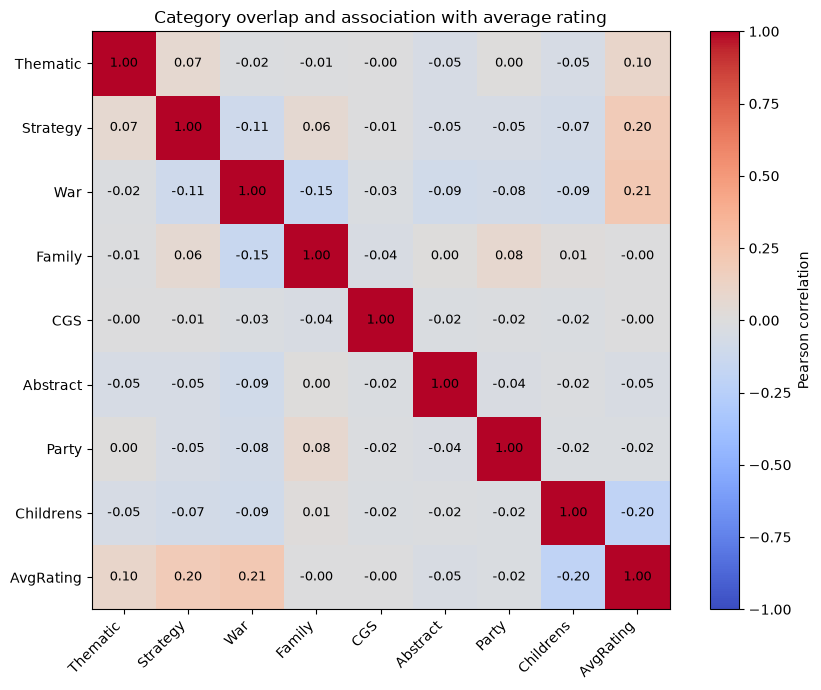

In [ ]:
corr = games_kristoffer[category_cols + ["AvgRating"]].corr()
labels = corr.columns.str.replace("Cat:", "", regex=False)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Category overlap and association with average rating")
plt.tight_layout()
plt.show()

### Interpreting category associations

A positive mean difference means that games with the category have a higher mean rating than games without it. Category correlations also describe overlapping membership. These are exploratory associations: complexity, publication year, popularity and differences in group size may contribute to them.

Keep all category indicators for correlation analysis despite incomplete coverage. Keep uncategorised games in the baseline and category-count-zero group; do not assign a category or remove a game because all eight indicators are zero.

Compare rating distributions across the number of recorded categories, retaining the zero-category group. Read each group together with its sample size.

,count,mean,median,std,q1,q3
Category count,,,,,,
0,11184,6.250,6.256,0.959,5.644,6.867
1,9167,6.612,6.654,0.880,6.070,7.224
2,1561,6.581,6.596,0.793,6.108,7.062
3,13,6.467,6.301,0.714,6.129,7.001


Pearson correlation: 0.172


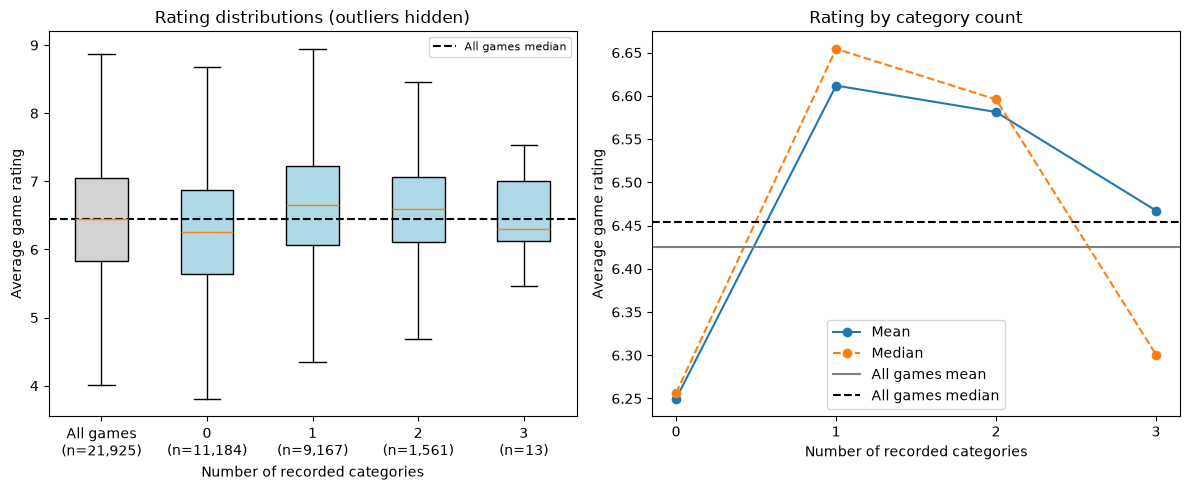

In [ ]:
category_cols = [c for c in games_kristoffer.columns if c.startswith("Cat:")]
category_count_data = games_kristoffer[["AvgRating"]].copy()
category_count_data["Category count"] = games_kristoffer[category_cols].sum(axis=1)
count_summary = category_count_data.groupby("Category count")["AvgRating"].agg(
    count="count", mean="mean", median="median", std="std",
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
)
display(count_summary.round(3))
print("Pearson correlation:", category_count_data.corr().loc["Category count", "AvgRating"].round(3))

baseline = games_kristoffer["AvgRating"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = count_summary.index
values = [category_count_data.loc[category_count_data["Category count"] == k, "AvgRating"].dropna() for k in counts]
boxes = axes[0].boxplot([baseline] + values, showfliers=False, patch_artist=True)
for i, box in enumerate(boxes["boxes"]):
    box.set_facecolor("lightgray" if i == 0 else "lightblue")
axes[0].set_xticks(range(1, len(counts) + 2), [f"All games\n(n={len(baseline):,})"] + [f"{int(k)}\n(n={len(v):,})" for k, v in zip(counts, values)])
axes[0].axhline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[0].legend(fontsize=8)
axes[0].set(xlabel="Number of recorded categories", ylabel="Average game rating", title="Rating distributions (outliers hidden)")
axes[1].plot(counts, count_summary["mean"], "o-", label="Mean")
axes[1].plot(counts, count_summary["median"], "o--", label="Median")
axes[1].axhline(baseline.mean(), color="gray", linestyle="-", label="All games mean")
axes[1].axhline(baseline.median(), color="black", linestyle="--", label="All games median")
axes[1].set_xticks(counts)
axes[1].set(xlabel="Number of recorded categories", ylabel="Average game rating", title="Rating by category count")
axes[1].legend()
plt.tight_layout()
plt.show()

Measure relative overlap using Jaccard similarity and directional percentages. Uncategorised games remain in the data but cannot contribute to a pair’s union.

,Category A,Category B,Games in both,Games in either,Jaccard overlap (%),A also in B (%),B also in A (%)
0,Strategy,Family,371,4264,8.70,16.00,16.02
1,Thematic,Strategy,236,3307,7.14,19.28,10.18
2,Family,Party,156,2800,5.57,6.74,24.38
3,Family,Childrens,112,3085,3.63,4.84,12.71
4,Family,Abstract,120,3311,3.62,5.18,10.76
5,Thematic,War,157,4597,3.42,12.83,4.45
6,Thematic,Family,116,3424,3.39,9.48,5.01
7,Thematic,Party,38,1826,2.08,3.10,5.94
8,Strategy,War,109,5740,1.90,4.70,3.09
9,Strategy,Abstract,46,3388,1.36,1.98,4.13


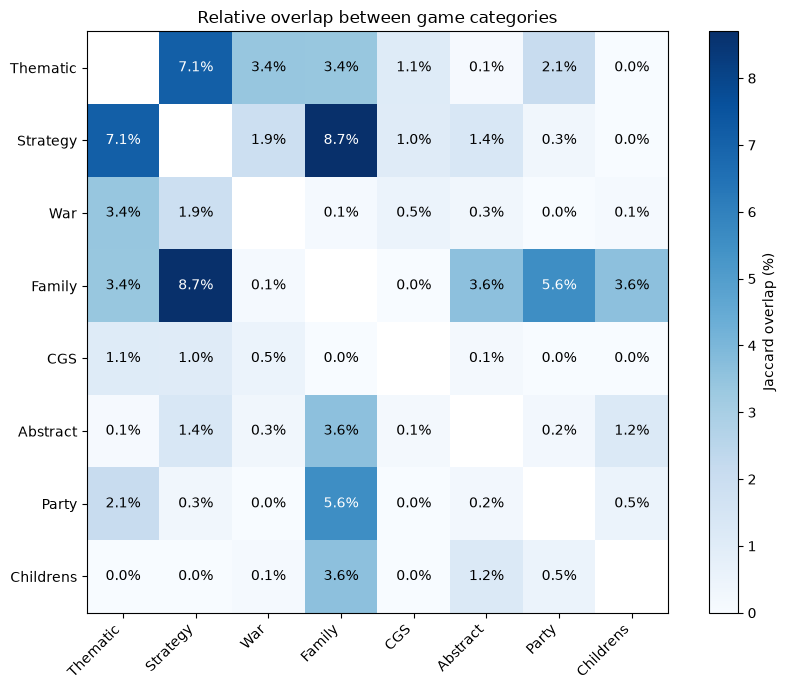

In [ ]:
category_cols = [c for c in games_kristoffer.columns if c.startswith("Cat:")]
membership = games_kristoffer[category_cols].eq(1)
labels = [c.replace("Cat:", "") for c in category_cols]
overlap_matrix = pd.DataFrame(index=labels, columns=labels, dtype=float)

rows = []
for a in category_cols:
    for b in category_cols:
        both = (membership[a] & membership[b]).sum()
        either = (membership[a] | membership[b]).sum()
        overlap_matrix.loc[
            a.replace("Cat:", ""), b.replace("Cat:", "")
        ] = both / either if either else np.nan

for a, b in combinations(category_cols, 2):
    both = (membership[a] & membership[b]).sum()
    either = (membership[a] | membership[b]).sum()
    count_a, count_b = membership[a].sum(), membership[b].sum()

    rows.append({
        "Category A": a.replace("Cat:", ""),
        "Category B": b.replace("Cat:", ""),
        "Games in both": both,
        "Games in either": either,
        "Jaccard overlap (%)": 100 * both / either if either else np.nan,
        "A also in B (%)": 100 * both / count_a if count_a else np.nan,
        "B also in A (%)": 100 * both / count_b if count_b else np.nan,
    })

overlap_summary = (
    pd.DataFrame(rows)
    .sort_values("Jaccard overlap (%)", ascending=False)
    .reset_index(drop=True)
)
display(overlap_summary.round(2))

plot_matrix = overlap_matrix.copy() * 100
for i in range(len(plot_matrix)):
    plot_matrix.iat[i, i] = np.nan

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(plot_matrix, cmap="Blues", vmin=0)

ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j:
            value = plot_matrix.iloc[i, j]
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                color="white" if value > plot_matrix.max().max() / 2 else "black",
            )

fig.colorbar(im, ax=ax, label="Jaccard overlap (%)")
ax.set_title("Relative overlap between game categories")
plt.tight_layout()
plt.show()

Report the strongest observed overlap directly from the computed table so the description stays consistent with the loaded source.

In [ ]:
top_pair = overlap_summary.iloc[0]
print(f"Largest Jaccard overlap: {top_pair['Category A']} + {top_pair['Category B']}, "
      f"{int(top_pair['Games in both']):,} shared games "
      f"({top_pair['Jaccard overlap (%)']:.2f}% of games in either category).")
uncategorised = games_kristoffer[category_cols].sum(axis=1).eq(0)
print(f"Uncategorised games retained: {uncategorised.sum():,} ({uncategorised.mean():.1%})")

Largest Jaccard overlap: Strategy + Family, 371 shared games (8.70% of games in either category).
Uncategorised games retained: 11,184 (51.0%)


## Combined dataset and exports

Retain the original combined notebook’s description, mechanics and designer enrichments and left joins. Drop `StdDev`, `ImagePath`, all ranks, community minimum/maximum playtime and the uninformative `NumComments` column. Keep the category indicators and both community player fields, with the modelling limitations discussed above. `LanguageEase` also remains available for inspection with its source values unchanged.

Build the combined dataframe with one row per original game. Validate enrichment IDs before joining to prevent duplicate matches from multiplying games.

In [ ]:
drop_cols = ["Description", "StdDev", "ImagePath", "ComMinPlaytime", "ComMaxPlaytime", "NumComments"]
original_cols = [col for col in games.columns if col not in drop_cols and "rank" not in col.lower()]
detailed = games_detailed[["id", "description", "boardgamemechanic", "boardgamedesigner"]].copy()
mechanics = games_mechanics[["ID", "Mechanics"]].dropna(subset=["ID"]).astype({"ID": int})

games_combined = (
    games[original_cols]
    .merge(detailed, left_on="BGGId", right_on="id", how="left", validate="one_to_one")
    .merge(mechanics, left_on="BGGId", right_on="ID", how="left", validate="one_to_one")
    .drop(columns=["id", "ID"])
)
for col in ["boardgamemechanic", "boardgamedesigner"]:
    games_combined[col] = games_combined[col].map(ast.literal_eval, na_action="ignore")
games_combined["Mechanics"] = games_combined["Mechanics"].str.split(r", (?!Different Worker Types)", regex=True)

assert len(games_combined) == len(games)
assert games_combined["BGGId"].equals(games["BGGId"])
assert not any("rank" in col.lower() for col in games_combined.columns)
assert not set(drop_cols).intersection(games_combined.columns)
assert games_combined[category_cols].equals(games[category_cols])
print(games_combined.shape)
display(games_combined.head())

(21925, 37)


,BGGId,Name,YearPublished,GameWeight,AvgRating,BayesAvgRating,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,...,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,description,boardgamemechanic,boardgamedesigner,Mechanics
0,1,Die Macher,1986,4.3206,7.61428,7.10363,3,5,14.366667,1.395833,...,0,0,0,0,0,0,Die Macher is a game about seven sequential po...,"[Alliances, Area Majority / Influence, Auction...",[Karl-Heinz Schmiel],"[Alliances, Area Majority / Influence, Auction..."
1,2,Dragonmaster,1981,1.9630,6.64537,5.78447,3,4,NaN,27.000000,...,0,0,0,0,0,0,Dragonmaster is a trick-taking card game based...,[Trick-taking],"[G. W. ""Jerry"" D'Arcey]",[Trick-taking]
2,3,Samurai,1998,2.4859,7.45601,7.23994,2,4,9.307692,1.000000,...,0,0,0,0,0,0,Samurai is set in medieval Japan. Players comp...,"[Area Majority / Influence, Hand Management, H...",[Reiner Knizia],"[Area Majority / Influence, Hand Management, H..."
3,4,Tal der Könige,1992,2.6667,6.60006,5.67954,2,4,13.000000,256.000000,...,0,0,0,0,0,0,When you see the triangular box and the luxuri...,"[Action Points, Area Majority / Influence, Auc...",[Christian Beierer],"[Action Points, Area Majority / Influence, Auc..."
4,5,Acquire,1964,2.5031,7.33861,7.14189,2,6,11.410256,21.152941,...,0,0,0,0,0,0,"In Acquire, each player strategically invests ...","[Hand Management, Investment, Market, Square G...",[Sid Sackson],"[Hand Management, Investment, Market, Ownershi..."


Inspect enrichment coverage and one cleaned full description, as in the original combined notebook.

In [ ]:
enrichment_cols = ["description", "boardgamemechanic", "boardgamedesigner", "Mechanics"]
display(games_combined[enrichment_cols].notna().mean().mul(100).round(2).rename("non-null %").to_frame())
display(games_combined.iloc[0]["description"])

,non-null %
description,98.04
boardgamemechanic,91.69
boardgamedesigner,95.55
Mechanics,85.15


'Die Macher is a game about seven sequential political races in different regions of Germany. Players are in charge of national political parties, and must manage limited resources to help their party to victory. The winning party will have the most victory points after all the regional elections. There are four different ways of scoring victory points. First, each regional election can supply one to eighty victory points, depending on the size of the region and how well your party does in it. Second, if a party wins a regional election and has some media influence in the region, then the party will receive some media-control victory points. Third, each party has a national party membership which will grow as the game progresses and this will supply a fair number of victory points. Lastly, parties score some victory points if their party platform matches the national opinions at the end of the game.\n\nThe 1986 edition featured four parties from the old West Germany and supported 3-4 p

Keep the original quantile sampling: select the 30 games closest to each average-rating quartile and export the 90 selected rows. Games can appear in more than one quantile if selections overlap.

In [ ]:
quantiles = games_combined["AvgRating"].quantile([0.25, 0.50, 0.75])

closest = [
    games_combined.loc[(games_combined["AvgRating"] - value).abs().nsmallest(30).index]
    .assign(Quantile=f"q{int(q * 100)}")
    for q, value in quantiles.items()
]
df_quantile_games = pd.concat(closest)[["BGGId", "Name", "AvgRating", "Quantile", "description"]]

excel_path = data_dir / "quantile_games.xlsx"
df_quantile_games.to_excel(excel_path, index=False)
print(f"Saved {len(df_quantile_games)} games to {excel_path}")

Saved 90 games to /Users/efh/Desktop/6. semester/Probalistic/PolyCats/Boardgames/Data/quantile_games.xlsx


Export the combined dataframe to CSV in the shared Data folder. List-valued mechanics and designer fields are stored as text in the CSV.

In [ ]:
csv_path = data_dir / "combined_boardgames.csv"
games_combined.to_csv(csv_path, index=False)
print(f"Saved {games_combined.shape[0]} rows and {games_combined.shape[1]} columns to {csv_path}")

Saved 21925 rows and 37 columns to /Users/efh/Desktop/6. semester/Probalistic/PolyCats/Boardgames/Data/combined_boardgames.csv
